**Step 1: Load Dataset & Understand Data**

In [ ]:

import pandas as pd
import numpy as np

# Load Titanic dataset
df = pd.read_csv("titanic.csv")

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Dataset shape
print("\nDataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


First 5 Rows:


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500



Dataset Shape: (887, 8)

Column Names:
['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'Siblings/Spouses Aboard', 'Parents/Children Aboard', 'Fare']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Survived                 887 non-null    int64  
 1   Pclass                   887 non-null    int64  
 2   Name                     887 non-null    object 
 3   Sex                      887 non-null    object 
 4   Age                      887 non-null    float64
 5   Siblings/Spouses Aboard  887 non-null    int64  
 6   Parents/Children Aboard  887 non-null    int64  
 7   Fare                     887 non-null    float64
dtypes: float64(2), int64(4), object(2)
memory usage: 55.6+ KB

Missing Values:
Survived                   0
Pclass                     0
Name                       0
Sex                 

In [3]:

# 1. Rename columns
df.rename(columns={
    'Siblings/Spouses Aboard': 'SibSp',
    'Parents/Children Aboard': 'Parch'
}, inplace=True)

# 2. Create FamilySize
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# 3. Create IsAlone
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# 4. Extract Title from passenger Name
df['Title'] = df['Name'].str.extract(r'^([A-Za-z]+)\.')

# 5. Display new features
print("New Features:")
display(df[['Name', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'Title']].head())

# 6. Check Title distribution
print("\nTitle Distribution:")
print(df['Title'].value_counts())

# 7. Check updated dataset shape
print("\nUpdated Dataset Shape:", df.shape)


New Features:


,Name,SibSp,Parch,FamilySize,IsAlone,Title
0,Mr. Owen Harris Braund,1,0,2,0,Mr
1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,1,0,2,0,Mrs
2,Miss. Laina Heikkinen,0,0,1,1,Miss
3,Mrs. Jacques Heath (Lily May Peel) Futrelle,1,0,2,0,Mrs
4,Mr. William Henry Allen,0,0,1,1,Mr



Title Distribution:
Title
Mr          513
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Mlle          2
Major         2
Col           2
Don           1
Mme           1
Ms            1
Sir           1
Lady          1
Capt          1
Jonkheer      1
Name: count, dtype: int64

Updated Dataset Shape: (887, 11)


**Step 2 – Part 2: Missing Values & Feature Selection**

In [4]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Select input features
features = [
    'Pclass', 'Sex', 'Age', 'SibSp',
    'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Title'
]

X = df[features]
y = df['Survived']

# Identify numerical and categorical columns
numerical_features = [
    'Pclass', 'Age', 'SibSp', 'Parch',
    'Fare', 'FamilySize', 'IsAlone'
]

categorical_features = ['Sex', 'Title']

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

# Display selected features
print("Input Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nNumerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)


Input Features (X):
   Pclass     Sex   Age  SibSp  Parch     Fare  FamilySize  IsAlone Title
0       3    male  22.0      1      0   7.2500           2        0    Mr
1       1  female  38.0      1      0  71.2833           2        0   Mrs
2       3  female  26.0      0      0   7.9250           1        1  Miss
3       1  female  35.0      1      0  53.1000           2        0   Mrs
4       3    male  35.0      0      0   8.0500           1        1    Mr

Target (y):
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

Numerical Features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Categorical Features: ['Sex', 'Title']

X Shape: (887, 9)
y Shape: (887,)


**Step 3: Train/Test Split (80:20)**

In [5]:

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Check survival distribution
print("\nTraining Set Survival Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Set Survival Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training Data Shape: (709, 9)
Testing Data Shape: (178, 9)

Training Target Shape: (709,)
Testing Target Shape: (178,)

Training Set Survival Distribution:
Survived
0    61.495063
1    38.504937
Name: proportion, dtype: float64

Testing Set Survival Distribution:
Survived
0    61.235955
1    38.764045
Name: proportion, dtype: float64


**Step 4: Model Training**

In [6]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Define Machine Learning models
models = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),

    'Random Forest': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ])
}

# Train both models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully!")


Logistic Regression trained successfully!
Random Forest trained successfully!


**Step 5: Model Evaluation – Predictions**

In [7]:

# Generate predictions using both models

predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    print(f"\n{name} Predictions:")
    print("First 10 Actual Values:    ", y_test.iloc[:10].values)
    print("First 10 Predicted Values: ", y_pred[:10])



Logistic Regression Predictions:
First 10 Actual Values:     [0 0 0 0 0 0 0 0 1 1]
First 10 Predicted Values:  [0 0 0 0 0 0 0 0 0 1]

Random Forest Predictions:
First 10 Actual Values:     [0 0 0 0 0 0 0 0 1 1]
First 10 Predicted Values:  [0 0 1 0 1 0 0 0 0 1]


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


**Step 5 – Part 1: Handle Rare Titles**

In [8]:

# Group rare titles into Other
common_titles = ['Mr', 'Mrs', 'Miss', 'Master']

df['Title'] = df['Title'].apply(
    lambda title: title if title in common_titles else 'Other'
)

# Check updated title distribution
print("Updated Title Distribution:")
print(df['Title'].value_counts())

# Recreate features and target
X = df[features]
y = df['Survived']

# Repeat train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Retrain both models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} retrained successfully!")

# Generate predictions again
predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)
    print(f"{name} predictions generated!")


Updated Title Distribution:
Title
Mr        513
Miss      182
Mrs       125
Master     40
Other      27
Name: count, dtype: int64
Logistic Regression retrained successfully!
Random Forest retrained successfully!
Logistic Regression predictions generated!
Random Forest predictions generated!


**Step 5 – Part 2: Model Evaluation**

In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Store evaluation results
results = {}

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }

    print(f"\n{name} Performance:")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))



Logistic Regression Performance:
Accuracy: 0.8202
Precision: 0.7846
Recall: 0.7391
F1-Score: 0.7612

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.87      0.86       109
           1       0.78      0.74      0.76        69

    accuracy                           0.82       178
   macro avg       0.81      0.81      0.81       178
weighted avg       0.82      0.82      0.82       178


Random Forest Performance:
Accuracy: 0.7472
Precision: 0.6714
Recall: 0.6812
F1-Score: 0.6763

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.79      0.79       109
           1       0.67      0.68      0.68        69

    accuracy                           0.75       178
   macro avg       0.73      0.74      0.73       178
weighted avg       0.75      0.75      0.75       178



**Step 5 – Part 3: Confusion Matrix**


Logistic Regression Confusion Matrix:
[[95 14]
 [18 51]]


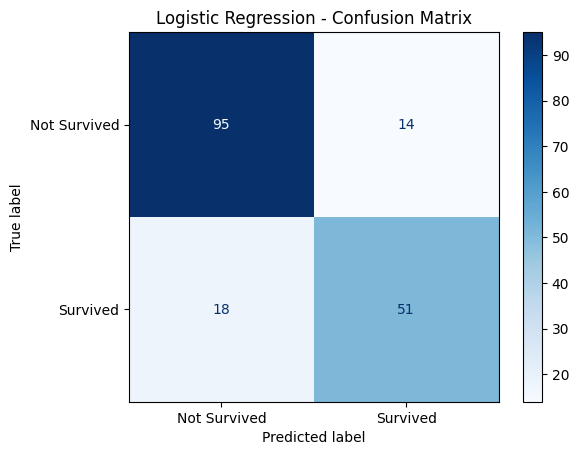


Random Forest Confusion Matrix:
[[86 23]
 [22 47]]


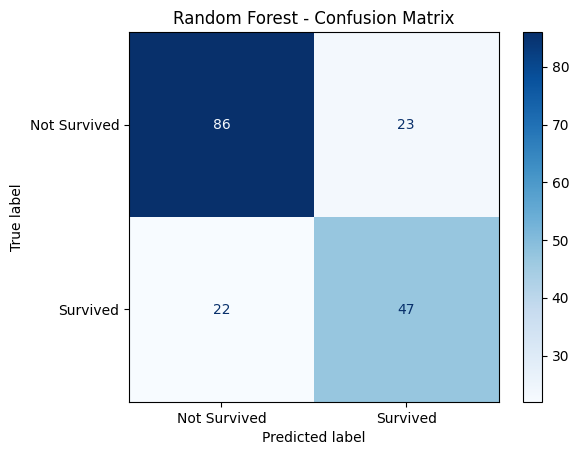

In [10]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plot confusion matrices for both models
for name, model in models.items():

    y_pred = predictions[name]

    cm = confusion_matrix(y_test, y_pred)

    print(f"\n{name} Confusion Matrix:")
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Not Survived', 'Survived']
    )

    disp.plot(cmap='Blues')
    plt.title(f'{name} - Confusion Matrix')
    plt.show()


**Step 5 – Part 4: ROC-AUC Score**

Logistic Regression ROC-AUC Score: 0.8716
Random Forest ROC-AUC Score: 0.7951


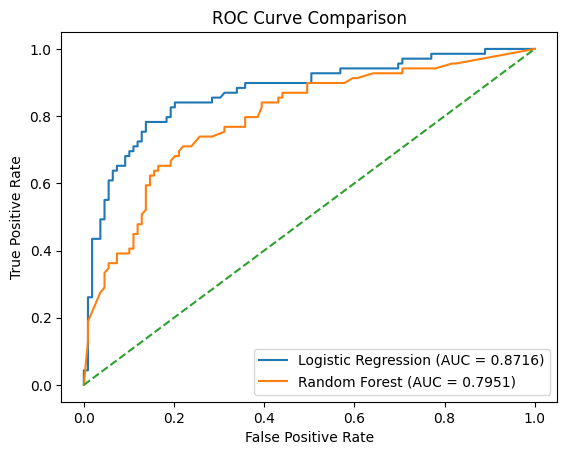

In [12]:

from sklearn.metrics import roc_auc_score, roc_curve

for name, model in models.items():

    # Get predicted probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC
    auc = roc_auc_score(y_test, y_prob)

    print(f"{name} ROC-AUC Score: {auc:.4f}")

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    # Plot ROC curve
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

# Reference line
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()


**Step 5 – Part 5: Model Comparison Table**

In [13]:

# Add ROC-AUC scores to the existing results
results['Logistic Regression']['ROC-AUC'] = 0.8716
results['Random Forest']['ROC-AUC'] = 0.7951

# Create comparison DataFrame
comparison_df = pd.DataFrame(results).T

print("Model Performance Comparison:")
display(comparison_df.round(4))


Model Performance Comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8202,0.7846,0.7391,0.7612,0.8716
Random Forest,0.7472,0.6714,0.6812,0.6763,0.7951


**Step 6: Feature Importance Analysis**

Feature Importance:


,Feature,Importance
4,num__Fare,0.251439
1,num__Age,0.239241
9,cat__Title_Mr,0.136668
7,cat__Sex_male,0.121221
0,num__Pclass,0.075190
5,num__FamilySize,0.044991
2,num__SibSp,0.037346
8,cat__Title_Miss,0.031585
10,cat__Title_Mrs,0.028247
3,num__Parch,0.018373


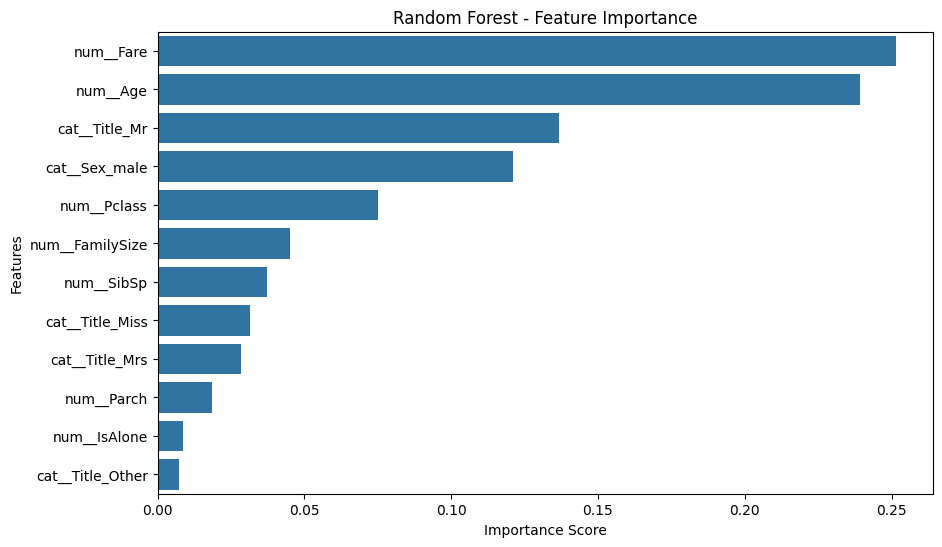

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get trained Random Forest model
rf_model = models['Random Forest']

# Get feature names after preprocessing
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance values
importances = rf_model.named_steps['classifier'].feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
display(importance_df)

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


**Step 7: Check Overfitting**

In [15]:

for name, model in models.items():

    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    print(f"\n{name}")
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Testing Accuracy:  {test_accuracy:.4f}")
    print(f"Accuracy Difference: {train_accuracy - test_accuracy:.4f}")



Logistic Regression
Training Accuracy: 0.8251
Testing Accuracy:  0.8202
Accuracy Difference: 0.0049

Random Forest
Training Accuracy: 0.9873
Testing Accuracy:  0.7472
Accuracy Difference: 0.2401


**Step 8: Cross-Validation**

In [16]:

from sklearn.model_selection import cross_val_score

for name, model in models.items():

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    print(f"\n{name}")
    print("Cross-Validation Scores:", cv_scores)
    print("Mean CV Accuracy:", round(cv_scores.mean(), 4))
    print("Standard Deviation:", round(cv_scores.std(), 4))



Logistic Regression
Cross-Validation Scores: [0.85211268 0.82394366 0.76760563 0.84507042 0.82269504]
Mean CV Accuracy: 0.8223
Standard Deviation: 0.0297

Random Forest
Cross-Validation Scores: [0.87323944 0.79577465 0.83802817 0.85211268 0.85106383]
Mean CV Accuracy: 0.842
Standard Deviation: 0.0257


**Step 9: Hyperparameter Tuning using GridSearchCV**

In [17]:

from sklearn.model_selection import GridSearchCV

# Random Forest pipeline
rf_pipeline = models['Random Forest']

# Parameters to test
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# Train using training data only
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross-Validation F1 Score:
0.8034


**Step 10: Evaluate Tuned Random Forest**

In [18]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Get best tuned model
best_rf_model = grid_search.best_estimator_

# Predictions on test data
tuned_predictions = best_rf_model.predict(X_test)
tuned_probabilities = best_rf_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("Tuned Random Forest Performance:")
print("Accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))
print("Precision:", round(precision_score(y_test, tuned_predictions), 4))
print("Recall:", round(recall_score(y_test, tuned_predictions), 4))
print("F1-Score:", round(f1_score(y_test, tuned_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, tuned_probabilities), 4))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_predictions))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, tuned_predictions))


Tuned Random Forest Performance:
Accuracy: 0.7921
Precision: 0.75
Recall: 0.6957
F1-Score: 0.7218
ROC-AUC: 0.8328

Confusion Matrix:
[[93 16]
 [21 48]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       109
           1       0.75      0.70      0.72        69

    accuracy                           0.79       178
   macro avg       0.78      0.77      0.78       178
weighted avg       0.79      0.79      0.79       178



**Step 11: Final Model Comparison**

In [19]:

final_results = {
    'Logistic Regression': {
        'Accuracy': accuracy_score(y_test, predictions['Logistic Regression']),
        'Precision': precision_score(y_test, predictions['Logistic Regression']),
        'Recall': recall_score(y_test, predictions['Logistic Regression']),
        'F1-Score': f1_score(y_test, predictions['Logistic Regression']),
        'ROC-AUC': roc_auc_score(
            y_test,
            models['Logistic Regression'].predict_proba(X_test)[:, 1]
        )
    },

    'Original Random Forest': {
        'Accuracy': accuracy_score(y_test, predictions['Random Forest']),
        'Precision': precision_score(y_test, predictions['Random Forest']),
        'Recall': recall_score(y_test, predictions['Random Forest']),
        'F1-Score': f1_score(y_test, predictions['Random Forest']),
        'ROC-AUC': roc_auc_score(
            y_test,
            models['Random Forest'].predict_proba(X_test)[:, 1]
        )
    },

    'Tuned Random Forest': {
        'Accuracy': accuracy_score(y_test, tuned_predictions),
        'Precision': precision_score(y_test, tuned_predictions),
        'Recall': recall_score(y_test, tuned_predictions),
        'F1-Score': f1_score(y_test, tuned_predictions),
        'ROC-AUC': roc_auc_score(y_test, tuned_probabilities)
    }
}

final_comparison = pd.DataFrame(final_results).T

print("Final Model Comparison:")
display(final_comparison.round(4))


Final Model Comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8202,0.7846,0.7391,0.7612,0.8716
Original Random Forest,0.7472,0.6714,0.6812,0.6763,0.7951
Tuned Random Forest,0.7921,0.7500,0.6957,0.7218,0.8328


**Step 12: Check Overfitting After Tuning**

In [20]:

# Compare training and testing accuracy
for name, model in {
    'Original Random Forest': models['Random Forest'],
    'Tuned Random Forest': best_rf_model
}.items():

    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

    print(f"\n{name}")
    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Testing Accuracy: {test_acc:.4f}")
    print(f"Accuracy Difference: {train_acc - test_acc:.4f}")



Original Random Forest
Training Accuracy: 0.9873
Testing Accuracy: 0.7472
Accuracy Difference: 0.2401

Tuned Random Forest
Training Accuracy: 0.9238
Testing Accuracy: 0.7921
Accuracy Difference: 0.1317


# Conclusion – Task 5: Machine Learning Modeling

In this project, a complete machine learning classification pipeline was developed using the Titanic dataset to predict passenger survival.

The dataset contained 887 records and 8 original columns. Data inspection, feature engineering, preprocessing, categorical encoding, and feature scaling were performed. New features such as FamilySize, IsAlone, and Title were created.

The dataset was divided into 80% training data and 20% testing data. Two classification algorithms, Logistic Regression and Random Forest, were trained and evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Confusion Matrix.

Logistic Regression achieved the best test performance, with 82.02% accuracy and an ROC-AUC score of 0.8716. Random Forest achieved 74.72% accuracy, while hyperparameter tuning improved its accuracy to 79.21%.

Cross-validation and GridSearchCV were also performed. Feature importance analysis identified Fare, Age, passenger Title, Sex, and Pclass as important predictive features. Overfitting analysis showed that tuning reduced the Random Forest training-testing accuracy gap.

**Final Result:** Logistic Regression was selected as the best-performing model for this dataset because it achieved the strongest overall test-set metrics and showed a smaller training-testing performance gap.

This project provided practical experience in data preprocessing, feature engineering, classification, model evaluation, cross-validation, hyperparameter tuning, and model interpretation.